### Task 1: Dataset Exploration and Understanding

In [4]:
# Copy a small, class-balanced subset of training images and their labels.
from pathlib import Path
import shutil
import pandas as pd

project_root = Path.cwd().resolve()
if not (project_root / "src").exists():
    project_root = project_root.parent

source_root = Path(
    r"C:\STUDY\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch"
)
target_root = project_root / "data"
target_root.mkdir(parents=True, exist_ok=True)

source_train_dir = source_root / "train" / "train"
target_train_dir = target_root / "train" / "train"
target_train_dir.mkdir(parents=True, exist_ok=True)

labels = pd.read_csv(source_root / "train_labels.csv")
subset = labels.groupby("class", group_keys=False).head(10).copy()
subset = subset[["image_id", "class"]].reset_index(drop=True)
subset["image_id"] = subset["image_id"].astype(int)

for _, row in subset.iterrows():
    image_id = row["image_id"]
    source_file = source_train_dir / f"{image_id:05d}.jpg"
    target_file = target_train_dir / f"{image_id:05d}.jpg"
    if source_file.exists():
        shutil.copy2(source_file, target_file)

subset.to_csv(target_root / "train_labels.csv", index=False)
print(f"Copied {len(subset)} training images to {target_train_dir}")
print(subset["class"].value_counts().sort_index().to_string())

# The test set is unlabeled, so copy the first 80 images (10 per class in the train subset).
source_test_dir = source_root / "test" / "test"
target_test_dir = target_root / "test" / "test"
target_test_dir.mkdir(parents=True, exist_ok=True)

test_files = sorted(path for path in source_test_dir.glob("*.jpg"))[: len(subset)]
for source_file in test_files:
    shutil.copy2(source_file, target_test_dir / source_file.name)
print(f"Copied {len(test_files)} test images to {target_test_dir}")

Copied 80 training images to C:\STUDY\kaggle-competition\data\train\train
class
CatEye      10
CatFace     10
CatMouth    10
CatNose     10
DogEye      10
DogFace     10
DogMouth    10
DogNose     10
Copied 80 test images to C:\STUDY\kaggle-competition\data\test\test


In [5]:
# Change this path later to use the full dataset.
dataset_root = project_root / "data"
train_dir = dataset_root / "train" / "train"
train_labels_path = dataset_root / "train_labels.csv"

test_dir = dataset_root / "test" / "test"

print(f"Dataset root: {dataset_root}")
print(
    f"Folders in dataset root: {[p.name for p in dataset_root.iterdir() if p.is_dir()]}"
)
print(f"Train folder: {train_dir}")
print(f"Test folder: {test_dir}")

Dataset root: C:\STUDY\kaggle-competition\data
Folders in dataset root: ['test', 'train']
Train folder: C:\STUDY\kaggle-competition\data\train\train
Test folder: C:\STUDY\kaggle-competition\data\test\test


In [6]:
# Inspect the labels for all labelled images and check they match the image files.
# Named all_labels (not train_labels) so it cannot be confused with the training split created later.
all_labels = pd.read_csv(train_labels_path)

print(f"Shape: {all_labels.shape}")
print(f"Columns and dtypes:\n{all_labels.dtypes.to_string()}")
print(f"\nMissing values:\n{all_labels.isna().sum().to_string()}")
print(f"\nDuplicate image_ids: {all_labels['image_id'].duplicated().sum()}")

label_ids = {f"{image_id:05d}" for image_id in all_labels["image_id"]}
file_ids = {path.stem for path in train_dir.glob("*.jpg")}
print(f"Labels without an image file: {sorted(label_ids - file_ids)}")
print(f"Image files without a label: {sorted(file_ids - label_ids)}")

print(
    f"\nUnique classes ({all_labels['class'].nunique()}): {sorted(all_labels['class'].unique())}"
)
print("\nFirst rows:")
print(all_labels.head().to_string(index=False))

Shape: (80, 2)
Columns and dtypes:
image_id    int64
class         str

Missing values:
image_id    0
class       0

Duplicate image_ids: 0
Labels without an image file: []
Image files without a label: []

Unique classes (8): ['CatEye', 'CatFace', 'CatMouth', 'CatNose', 'DogEye', 'DogFace', 'DogMouth', 'DogNose']

First rows:
 image_id    class
        1   DogEye
        2 DogMouth
        3  DogFace
        4  DogNose
        5  DogNose


In [7]:
# Inspect the unlabeled test images.
from collections import Counter
from PIL import Image

test_files = sorted(test_dir.glob("*.jpg"))
print(f"Test images: {len(test_files)}")
print(f"First files: {[p.name for p in test_files[:5]]}")
print(f"File types in folder: {Counter(p.suffix for p in test_dir.iterdir())}")

sizes, modes = Counter(), Counter()
for p in test_files:
    with Image.open(p) as img:
        sizes[img.size] += 1
        modes[img.mode] += 1
print(f"Test image sizes: {sizes.most_common(5)}")
print(f"Test image modes: {dict(modes)}")

Test images: 80
First files: ['00001.jpg', '00002.jpg', '00003.jpg', '00004.jpg', '00005.jpg']
File types in folder: Counter({'.jpg': 80})
Test image sizes: [((60, 60), 2), ((192, 192), 2), ((40, 40), 2), ((59, 59), 2), ((40, 30), 2)]
Test image modes: {'RGB': 80}


In [8]:
# Report the number of images in each class.
import pandas as pd

if train_dir.exists():
    image_files = sorted(path for path in train_dir.iterdir() if path.is_file())
    print(f"  Image count: {len(image_files)}")
    print(f"  Sample files: {[path.name for path in image_files[:5]]}")
    print(f"  File extensions: {sorted({path.suffix.lower() for path in image_files})}")
else:
    raise FileNotFoundError(f"Training image directory not found: {train_dir}")

dataset_labels = pd.read_csv(train_labels_path)
print(f"\nTraining labels shape: {dataset_labels.shape}")
print(f"Training label columns: {dataset_labels.columns.tolist()}")
print("Training examples per class:")
print(dataset_labels["class"].value_counts().sort_index().to_string())
print("\nTraining label samples:")
print(dataset_labels.head().to_string(index=False))

  Image count: 80
  Sample files: ['00001.jpg', '00002.jpg', '00003.jpg', '00004.jpg', '00005.jpg']
  File extensions: ['.jpg']

Training labels shape: (80, 2)
Training label columns: ['image_id', 'class']
Training examples per class:
class
CatEye      10
CatFace     10
CatMouth    10
CatNose     10
DogEye      10
DogFace     10
DogMouth    10
DogNose     10

Training label samples:
 image_id    class
        1   DogEye
        2 DogMouth
        3  DogFace
        4  DogNose
        5  DogNose


In [9]:
# Report class imbalance in the training labels.
class_counts = dataset_labels["class"].value_counts().sort_index()
class_percentages = (class_counts / class_counts.sum() * 100).round(2)
imbalance_ratio = class_counts.max() / class_counts.min()

print(f"Classes: {len(class_counts)}")
print(f"Largest class: {class_counts.idxmax()} ({class_counts.max()} images)")
print(f"Smallest class: {class_counts.idxmin()} ({class_counts.min()} images)")
print(f"Imbalance ratio (largest / smallest): {imbalance_ratio:.2f}")
print(pd.DataFrame({"count": class_counts, "percent": class_percentages}).to_string())

if imbalance_ratio == 1:
    print("\nClasses are perfectly balanced.")
else:
    print("\nClasses are imbalanced; consider class weights or resampling.")

Classes: 8
Largest class: CatEye (10 images)
Smallest class: CatEye (10 images)
Imbalance ratio (largest / smallest): 1.00
          count  percent
class                   
CatEye       10     12.5
CatFace      10     12.5
CatMouth     10     12.5
CatNose      10     12.5
DogEye       10     12.5
DogFace      10     12.5
DogMouth     10     12.5
DogNose      10     12.5

Classes are perfectly balanced.


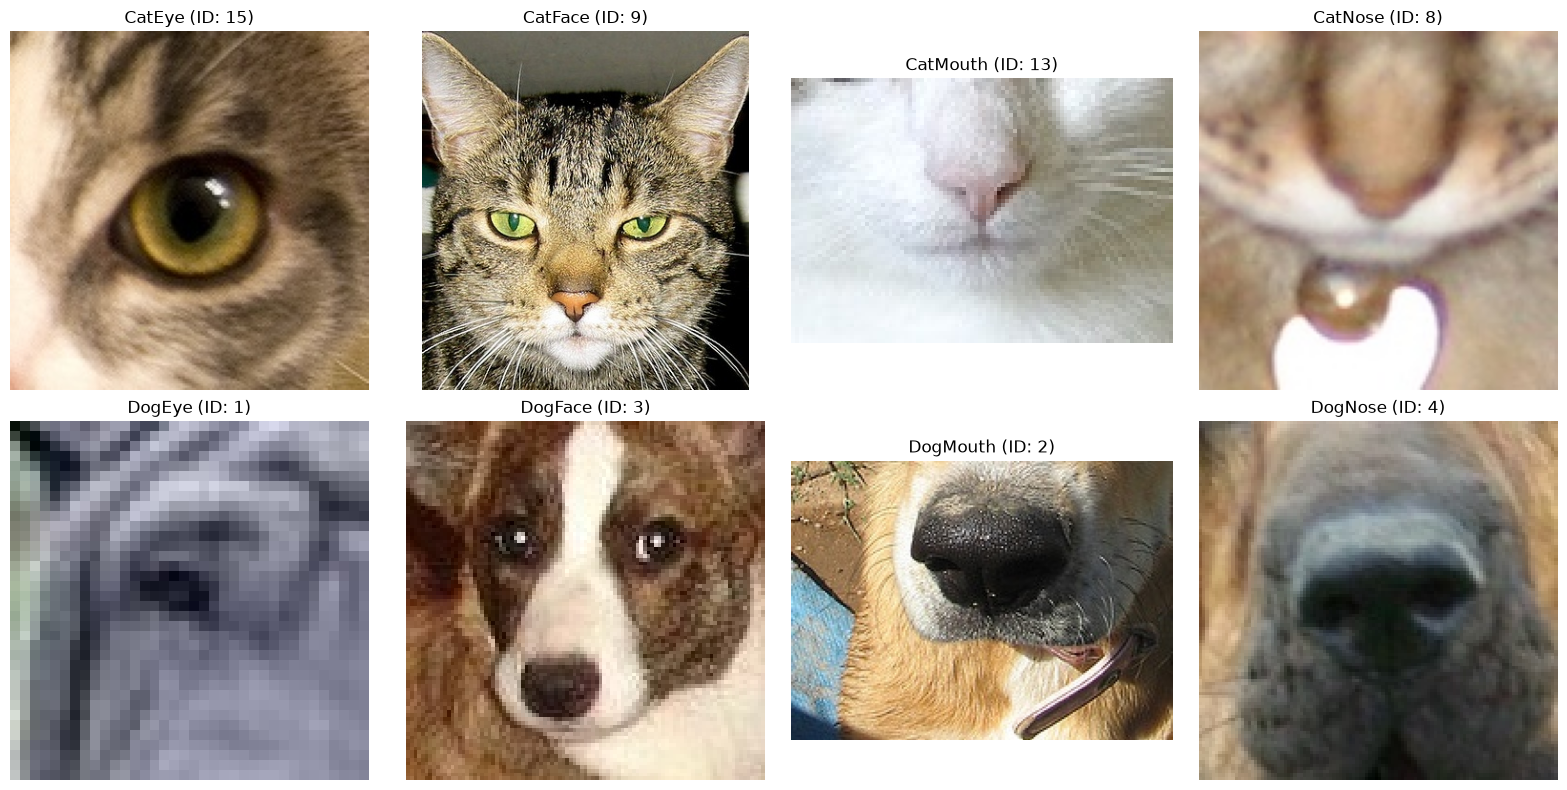

In [10]:
# Display one representative training image for each class.
from math import ceil
from PIL import Image
import matplotlib.pyplot as plt

representatives = dataset_labels.groupby("class", sort=True).first().reset_index()
num_images = len(representatives)
num_columns = min(4, num_images)
num_rows = ceil(num_images / num_columns)

fig, axes = plt.subplots(num_rows, num_columns, figsize=(4 * num_columns, 4 * num_rows))
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for ax, (_, sample) in zip(axes, representatives.iterrows()):
    image_path = train_dir / f"{int(sample['image_id']):05d}.jpg"
    if not image_path.is_file():
        raise FileNotFoundError(
            f"Image for class {sample['class']} not found: {image_path}"
        )

    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(f"{sample['class']} (ID: {int(sample['image_id'])})")
    ax.axis("off")

for ax in axes[num_images:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [11]:
# Find training images whose dimensions differ from the most common size.
from collections import Counter
from PIL import Image

image_dimensions = {}
for image_path in sorted(train_dir.glob("*")):
    if image_path.is_file():
        with Image.open(image_path) as image:
            image_dimensions[image_path] = image.size

if not image_dimensions:
    raise ValueError(f"No images found in {train_dir}")

dimension_counts = Counter(image_dimensions.values())
common_size, common_count = dimension_counts.most_common(1)[0]
print(f"Checked {len(image_dimensions)} images.")
print("Image dimensions and counts:")
for dimensions, count in sorted(dimension_counts.items()):
    print(f"  {dimensions[0]}x{dimensions[1]}: {count}")

inconsistent_images = {
    image_path: dimensions
    for image_path, dimensions in image_dimensions.items()
    if dimensions != common_size
}
if inconsistent_images:
    print(
        f"\nFound {len(inconsistent_images)} images differing from the most common size ({common_size[0]}x{common_size[1]}):"
    )
    for image_path, dimensions in inconsistent_images.items():
        print(f"  {image_path.name}: {dimensions[0]}x{dimensions[1]}")
else:
    print(f"\nAll images have the same size: {common_size[0]}x{common_size[1]}.")

Checked 80 images.
Image dimensions and counts:
  24x24: 2
  26x26: 1
  28x28: 1
  32x32: 1
  34x24: 1
  34x34: 2
  36x36: 3
  38x38: 2
  40x40: 1
  42x42: 2
  50x37: 1
  52x52: 1
  54x40: 1
  54x54: 1
  56x56: 1
  59x59: 1
  60x60: 1
  62x62: 1
  64x44: 1
  64x47: 1
  64x64: 1
  66x66: 1
  68x50: 1
  68x68: 2
  70x70: 1
  74x74: 1
  78x54: 1
  78x78: 2
  80x56: 1
  90x64: 1
  90x90: 1
  94x66: 1
  94x70: 1
  96x96: 1
  97x97: 1
  98x68: 1
  100x100: 1
  104x77: 1
  106x106: 1
  108x108: 1
  110x110: 1
  112x112: 1
  112x163: 1
  114x114: 1
  122x90: 1
  123x115: 1
  128x128: 1
  130x130: 1
  140x140: 1
  142x105: 1
  145x145: 1
  149x148: 1
  155x154: 1
  157x157: 1
  158x158: 1
  158x163: 1
  166x116: 1
  171x210: 1
  176x124: 1
  182x135: 1
  188x182: 1
  191x191: 1
  207x232: 1
  208x208: 1
  214x157: 1
  250x358: 1
  256x288: 1
  266x266: 1
  316x222: 1
  343x376: 1
  387x388: 1
  478x585: 1

Found 77 images differing from the most common size (36x36):
  00002.jpg: 214x157
  00003

In [12]:
# Find potentially blurry training images using Laplacian variance.
import numpy as np
from PIL import Image
from scipy.ndimage import laplace

# Lower scores indicate less visible detail; tune this threshold for the dataset.
blur_threshold = 50.0
blur_scores = {}

for image_path in sorted(train_dir.glob("*")):
    if image_path.is_file():
        with Image.open(image_path) as image:
            grayscale = image.convert("L").resize((128, 128))
            pixels = np.asarray(grayscale, dtype=np.float32)
        blur_scores[image_path] = float(laplace(pixels).var())

if not blur_scores:
    raise ValueError(f"No images found in {train_dir}")

blurry_images = {
    image_path: score
    for image_path, score in blur_scores.items()
    if score < blur_threshold
}
print(
    f"Checked {len(blur_scores)} images using a blur threshold of {blur_threshold:.1f}."
)
if blurry_images:
    print(f"Potentially blurry images: {len(blurry_images)}")
    for image_path, score in sorted(blurry_images.items(), key=lambda item: item[1]):
        print(f"  {image_path.name}: sharpness score = {score:.2f}")
else:
    print("No images fell below the blur threshold.")

Checked 80 images using a blur threshold of 50.0.
Potentially blurry images: 24
  00033.jpg: sharpness score = 2.67
  00086.jpg: sharpness score = 4.68
  00075.jpg: sharpness score = 6.04
  00072.jpg: sharpness score = 6.53
  00064.jpg: sharpness score = 8.05
  00036.jpg: sharpness score = 8.58
  00010.jpg: sharpness score = 10.25
  00052.jpg: sharpness score = 10.37
  00030.jpg: sharpness score = 10.79
  00066.jpg: sharpness score = 11.26
  00019.jpg: sharpness score = 12.37
  00001.jpg: sharpness score = 14.66
  00048.jpg: sharpness score = 17.82
  00005.jpg: sharpness score = 17.97
  00039.jpg: sharpness score = 19.60
  00006.jpg: sharpness score = 20.58
  00045.jpg: sharpness score = 22.41
  00055.jpg: sharpness score = 22.82
  00125.jpg: sharpness score = 23.37
  00038.jpg: sharpness score = 26.43
  00027.jpg: sharpness score = 29.85
  00026.jpg: sharpness score = 44.85
  00060.jpg: sharpness score = 47.67
  00109.jpg: sharpness score = 47.69


In [13]:
# Find corrupted or unreadable image files in the training folder.
from PIL import Image, UnidentifiedImageError

corrupted_files = {}
checked_files = [path for path in sorted(train_dir.glob("*")) if path.is_file()]

for image_path in checked_files:
    try:
        with Image.open(image_path) as image:
            image.verify()
        # verify() does not catch every problem, so fully decode the image as well.
        with Image.open(image_path) as image:
            image.load()
    except (UnidentifiedImageError, OSError, SyntaxError, ValueError) as error:
        corrupted_files[image_path] = f"{type(error).__name__}: {error}"

print(f"Checked {len(checked_files)} files.")
if corrupted_files:
    print(f"Found {len(corrupted_files)} corrupted files:")
    for image_path, reason in corrupted_files.items():
        print(f"  {image_path.name}: {reason}")
else:
    print("No corrupted files found.")

Checked 80 files.
No corrupted files found.


In [14]:
# Find exact duplicate images by hashing file contents.
import hashlib
from collections import defaultdict

files_by_hash = defaultdict(list)
checked_files = [path for path in sorted(train_dir.glob("*")) if path.is_file()]

for image_path in checked_files:
    files_by_hash[hashlib.sha256(image_path.read_bytes()).hexdigest()].append(
        image_path
    )

duplicate_groups = [paths for paths in files_by_hash.values() if len(paths) > 1]

print(f"Checked {len(checked_files)} files.")
if duplicate_groups:
    extra_copies = sum(len(paths) - 1 for paths in duplicate_groups)
    print(
        f"Found {len(duplicate_groups)} groups of duplicates ({extra_copies} redundant files):"
    )
    for paths in duplicate_groups:
        print("  " + ", ".join(path.name for path in paths))
else:
    print("No duplicate images found.")

Checked 80 files.
No duplicate images found.


In [15]:
# Check for exact and near-duplicate images, both within train and between train and test.
# Exact copies share a file hash; near-duplicates (resized, re-saved or lightly edited copies)
# are found with a perceptual difference hash (dHash) and a small Hamming distance.
import numpy as np
from PIL import Image

NEAR_DUPLICATE_MAX_DISTANCE = 4  # out of 64 bits


def dhash(path, hash_size=8):
    with Image.open(path) as img:
        small = img.convert("L").resize((hash_size + 1, hash_size), Image.LANCZOS)
    pixels = np.asarray(small, dtype=np.int16)
    return (pixels[:, 1:] > pixels[:, :-1]).flatten()


def file_hash(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


train_files = sorted(train_dir.glob("*.jpg"))
test_files = sorted(test_dir.glob("*.jpg"))

# 1. Exact duplicates between train and test.
test_hashes = {file_hash(path): path for path in test_files}
exact_matches = [
    (path, test_hashes[file_hash(path)])
    for path in train_files
    if file_hash(path) in test_hashes
]
print(f"Exact duplicates between train and test: {len(exact_matches)}")
for train_path, test_path in exact_matches:
    print(f"  train/{train_path.name} == test/{test_path.name}")

# 2. Near-duplicates within train and between train and test.
train_hashes = np.array([dhash(path) for path in train_files])
test_dhashes = np.array([dhash(path) for path in test_files])

within_train = []
for i in range(len(train_files)):
    for j in range(i + 1, len(train_files)):
        distance = int(np.count_nonzero(train_hashes[i] != train_hashes[j]))
        if distance <= NEAR_DUPLICATE_MAX_DISTANCE:
            within_train.append((train_files[i], train_files[j], distance))

train_vs_test = []
for i, train_path in enumerate(train_files):
    for j, test_path in enumerate(test_files):
        distance = int(np.count_nonzero(train_hashes[i] != test_dhashes[j]))
        if distance <= NEAR_DUPLICATE_MAX_DISTANCE:
            train_vs_test.append((train_path, test_path, distance))

print(
    f"\nNear-duplicate pairs within train (distance <= {NEAR_DUPLICATE_MAX_DISTANCE}): {len(within_train)}"
)
for a, b, distance in within_train:
    print(f"  train/{a.name} ~ train/{b.name} (distance {distance})")
print(f"Near-duplicate pairs between train and test: {len(train_vs_test)}")
for a, b, distance in train_vs_test:
    print(f"  train/{a.name} ~ test/{b.name} (distance {distance})")

# Show the closest matches for visual review.
pairs = sorted(within_train + train_vs_test, key=lambda pair: pair[2])[:4]
if pairs:
    fig, axes = plt.subplots(
        len(pairs), 2, figsize=(5, 2.5 * len(pairs)), squeeze=False
    )
    for row, (a, b, distance) in enumerate(pairs):
        for ax, path in zip(axes[row], (a, b)):
            with Image.open(path) as img:
                ax.imshow(img)
            ax.set_title(
                f"{path.parent.parent.name}/{path.name} (d={distance})", fontsize=8
            )
            ax.axis("off")
    plt.tight_layout()
    plt.show()

if not (exact_matches or within_train or train_vs_test):
    print(
        "\nNo exact or near-duplicate images found, so there is no duplicate-based leakage."
    )

Exact duplicates between train and test: 0

Near-duplicate pairs within train (distance <= 4): 0
Near-duplicate pairs between train and test: 0

No exact or near-duplicate images found, so there is no duplicate-based leakage.


In [16]:
# Create a stratified 80/20 train/validation split.
from sklearn.model_selection import train_test_split

train_labels, validation_labels = train_test_split(
    dataset_labels,
    test_size=0.2,
    random_state=42,
    stratify=dataset_labels["class"],
)
print(f"\nTraining split: {len(train_labels)} samples")
print(f"Validation split: {len(validation_labels)} samples")
print("Training split examples per class:")
print(train_labels["class"].value_counts().sort_index().to_string())
print("\nValidation split examples per class:")
print(validation_labels["class"].value_counts().sort_index().to_string())


Training split: 64 samples
Validation split: 16 samples
Training split examples per class:
class
CatEye      8
CatFace     8
CatMouth    8
CatNose     8
DogEye      8
DogFace     8
DogMouth    8
DogNose     8

Validation split examples per class:
class
CatEye      2
CatFace     2
CatMouth    2
CatNose     2
DogEye      2
DogFace     2
DogMouth    2
DogNose     2


In [17]:
# Guard against leakage: no image may appear in both splits, and no labelled image may be dropped.
train_ids = set(train_labels["image_id"])
validation_ids = set(validation_labels["image_id"])

assert train_ids.isdisjoint(
    validation_ids
), "Leakage: image_ids appear in both train and validation."
assert len(train_labels) + len(validation_labels) == len(
    dataset_labels
), "Split dropped or duplicated rows."
assert train_ids | validation_ids == set(
    dataset_labels["image_id"]
), "Split does not cover all labelled images."
print(
    "Leakage check passed: train and validation image_ids are disjoint and cover every labelled image."
)

Leakage check passed: train and validation image_ids are disjoint and cover every labelled image.


In [18]:
# Compare class balance in the training and validation splits.
all_classes = dataset_labels["class"].dropna().unique()
if len(all_classes) == 0:
    raise ValueError("No class labels were found in the dataset.")

for split_name, split_labels in (
    ("Training", train_labels),
    ("Validation", validation_labels),
):
    class_counts = (
        split_labels["class"]
        .value_counts()
        .reindex(all_classes, fill_value=0)
        .sort_index()
    )
    if class_counts.sum() == 0:
        raise ValueError(
            f"No class labels were found in the {split_name.lower()} split."
        )

    class_percentages = (class_counts / class_counts.sum() * 100).round(2)
    print(f"{split_name} samples per class:")
    print(class_counts.to_string())
    print(f"\n{split_name} percentage per class:")
    print(class_percentages.astype(str).add("%").to_string())

    if class_counts.min() == 0:
        print(f"\n{split_name} split is imbalanced: at least one class has no samples.")
    elif class_counts.nunique() == 1:
        print(
            f"\n{split_name} split is balanced: every class has the same number of samples."
        )
    else:
        imbalance_ratio = class_counts.max() / class_counts.min()
        print(f"\n{split_name} split is imbalanced.")
        print(f"Largest-to-smallest class ratio: {imbalance_ratio:.2f}:1")
    print()

Training samples per class:
class
CatEye      8
CatFace     8
CatMouth    8
CatNose     8
DogEye      8
DogFace     8
DogMouth    8
DogNose     8

Training percentage per class:
class
CatEye      12.5%
CatFace     12.5%
CatMouth    12.5%
CatNose     12.5%
DogEye      12.5%
DogFace     12.5%
DogMouth    12.5%
DogNose     12.5%

Training split is balanced: every class has the same number of samples.

Validation samples per class:
class
CatEye      2
CatFace     2
CatMouth    2
CatNose     2
DogEye      2
DogFace     2
DogMouth    2
DogNose     2

Validation percentage per class:
class
CatEye      12.5%
CatFace     12.5%
CatMouth    12.5%
CatNose     12.5%
DogEye      12.5%
DogFace     12.5%
DogMouth    12.5%
DogNose     12.5%

Validation split is balanced: every class has the same number of samples.



### Task 2: Data Preprocessing and Pipeline Preparation

Resized image sizes and counts: {(224, 224): 160}


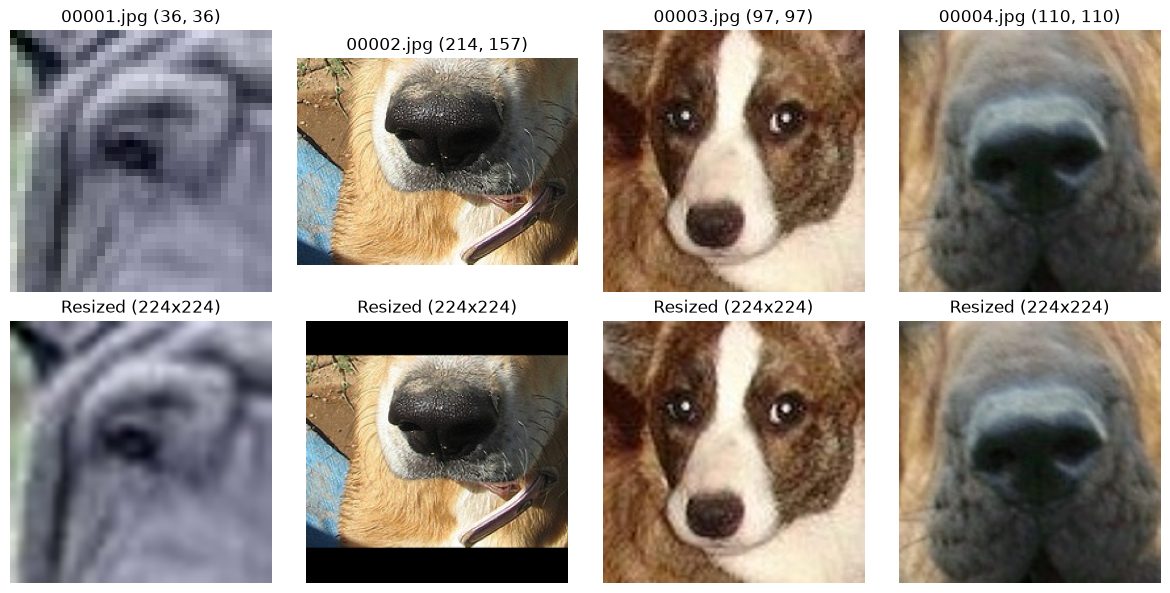

In [19]:
# Resize images to 224x224, the standard input size for ImageNet-pretrained models.
# Images are padded to a square first so the animal features are not stretched.
from PIL import Image, ImageOps

IMAGE_SIZE = 224


def resize_image(image, size=IMAGE_SIZE):
    image = image.convert("RGB")
    side = max(image.size)
    delta_w, delta_h = side - image.width, side - image.height
    padding = (
        delta_w // 2,
        delta_h // 2,
        delta_w - delta_w // 2,
        delta_h - delta_h // 2,
    )
    image = ImageOps.expand(image, border=padding, fill=(0, 0, 0))
    return image.resize((size, size), Image.BICUBIC)


# Check that every train and test image ends up with the same size.
resized_sizes = Counter()
for path in sorted(train_dir.glob("*.jpg")) + sorted(test_dir.glob("*.jpg")):
    with Image.open(path) as img:
        resized_sizes[resize_image(img).size] += 1
print(f"Resized image sizes and counts: {dict(resized_sizes)}")

# Show a few originals next to their resized versions.
sample_paths = sorted(train_dir.glob("*.jpg"))[:4]
fig, axes = plt.subplots(2, len(sample_paths), figsize=(3 * len(sample_paths), 6))
for column, path in enumerate(sample_paths):
    with Image.open(path) as img:
        axes[0, column].imshow(img)
        axes[0, column].set_title(f"{path.name} {img.size}")
        axes[1, column].imshow(resize_image(img))
        axes[1, column].set_title(f"Resized ({IMAGE_SIZE}x{IMAGE_SIZE})")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

Raw pixels:        min=0.0, max=255.0, mean per channel=[116.  103.9  94.1]
Normalised pixels: min=-2.12, max=2.64, mean per channel=[-0.13 -0.22 -0.17], std per channel=[1.32 1.27 1.25]


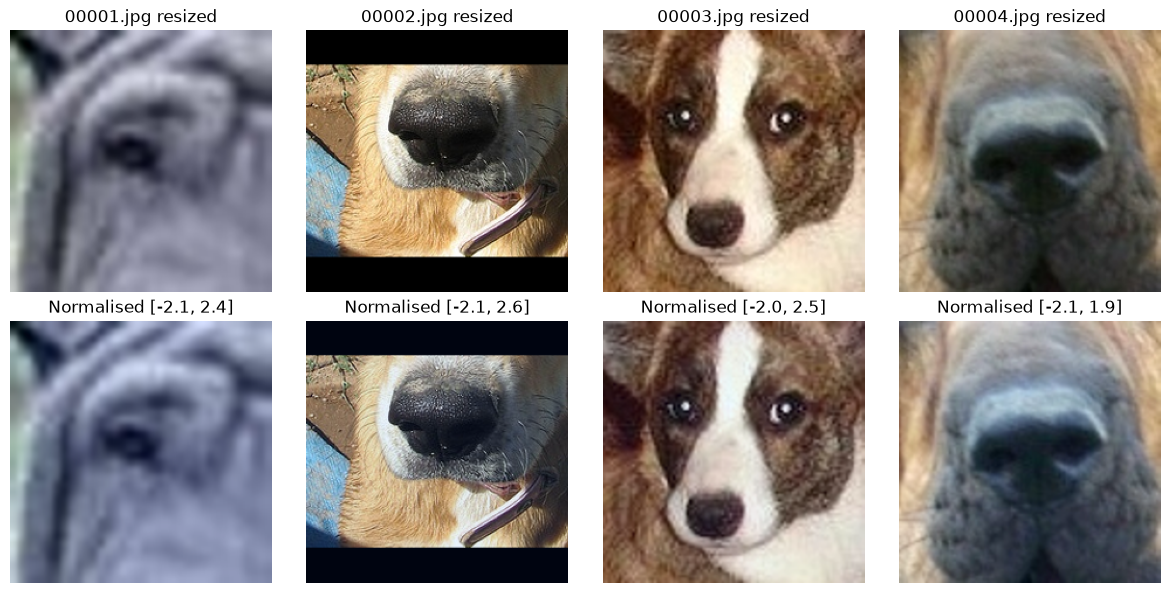

In [20]:
# Rescale pixels to [0, 1], then standardise with the ImageNet mean and std.
# Fixed ImageNet statistics match pretrained models and avoid fitting anything on the data (no leakage).
import numpy as np

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def normalise_array(image):
    # Rescale an already-resized PIL image to [0, 1] and standardise with ImageNet statistics.
    array = np.asarray(image, dtype=np.float32) / 255.0
    return (array - IMAGENET_MEAN) / IMAGENET_STD


def normalise_image(image):
    return normalise_array(resize_image(image))


# Compare pixel statistics before and after normalisation on the training images.
raw_pixels, normalised_pixels = [], []
for path in sorted(train_dir.glob("*.jpg")):
    with Image.open(path) as img:
        raw_pixels.append(
            np.asarray(resize_image(img), dtype=np.float32).reshape(-1, 3)
        )
        normalised_pixels.append(normalise_image(img).reshape(-1, 3))
raw_pixels = np.concatenate(raw_pixels)
normalised_pixels = np.concatenate(normalised_pixels)

print(
    f"Raw pixels:        min={raw_pixels.min():.1f}, max={raw_pixels.max():.1f}, "
    f"mean per channel={raw_pixels.mean(axis=0).round(1)}"
)
print(
    f"Normalised pixels: min={normalised_pixels.min():.2f}, max={normalised_pixels.max():.2f}, "
    f"mean per channel={normalised_pixels.mean(axis=0).round(2)}, "
    f"std per channel={normalised_pixels.std(axis=0).round(2)}"
)

# Draw resized and normalised versions. Normalised values fall outside [0, 1],
# so they are min-max scaled for display only; the data itself is unchanged.
sample_paths = sorted(train_dir.glob("*.jpg"))[:4]
fig, axes = plt.subplots(2, len(sample_paths), figsize=(3 * len(sample_paths), 6))
for column, path in enumerate(sample_paths):
    with Image.open(path) as img:
        normalised = normalise_image(img)
        axes[0, column].imshow(resize_image(img))
        axes[0, column].set_title(f"{path.name} resized")
        displayed = (normalised - normalised.min()) / (
            normalised.max() - normalised.min()
        )
        axes[1, column].imshow(displayed)
        axes[1, column].set_title(
            f"Normalised [{normalised.min():.1f}, {normalised.max():.1f}]"
        )
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

In [21]:
# Encode class names as integer labels (0-7), as expected by PyTorch cross-entropy loss.
# The mapping comes from the sorted class names, so it is stable between runs.
class_names = sorted(dataset_labels["class"].unique())
class_to_idx = {name: index for index, name in enumerate(class_names)}
idx_to_class = {index: name for name, index in class_to_idx.items()}
NUM_CLASSES = len(class_names)

train_labels = train_labels.assign(label=train_labels["class"].map(class_to_idx))
validation_labels = validation_labels.assign(
    label=validation_labels["class"].map(class_to_idx)
)

print(f"Number of classes: {NUM_CLASSES}")
print("Class to index mapping:")
for name, index in class_to_idx.items():
    print(f"  {index}: {name}")

assert train_labels["label"].notna().all() and validation_labels["label"].notna().all()
assert all(idx_to_class[index] == name for name, index in class_to_idx.items())
print("\nTraining labels with encoded values:")
print(train_labels.head().to_string(index=False))

Number of classes: 8
Class to index mapping:
  0: CatEye
  1: CatFace
  2: CatMouth
  3: CatNose
  4: DogEye
  5: DogFace
  6: DogMouth
  7: DogNose

Training labels with encoded values:
 image_id    class  label
       55  DogNose      7
       24   DogEye      4
        6   DogEye      4
       79 CatMouth      2
       83  DogFace      5


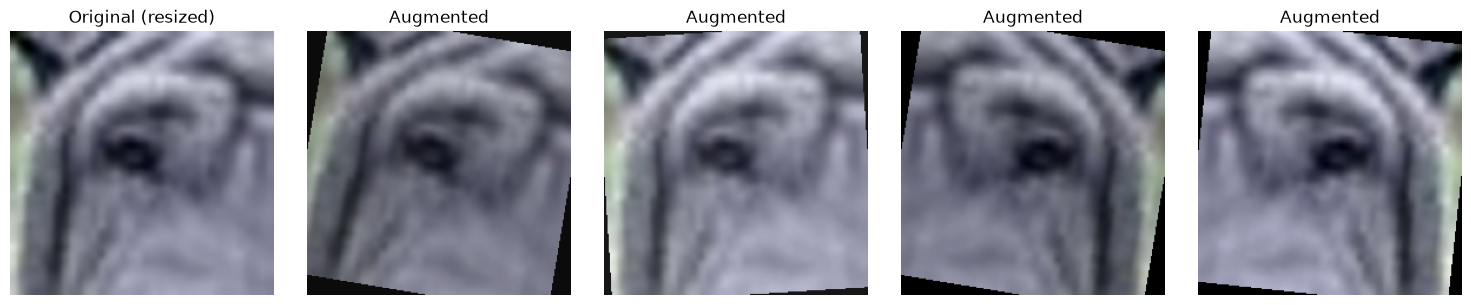

In [22]:
# Light data augmentation for the training set only (validation and test are never augmented).
# Horizontal flip, small rotation and mild brightness/contrast changes keep the class label valid.
# Vertical flips, heavy crops and strong colour shifts are avoided.
import random
from PIL import ImageEnhance


def augment_image(image, rng=random):
    image = resize_image(image)
    if rng.random() < 0.5:
        image = ImageOps.mirror(image)
    image = image.rotate(
        rng.uniform(-10, 10), resample=Image.BICUBIC, fillcolor=(0, 0, 0)
    )
    image = ImageEnhance.Brightness(image).enhance(rng.uniform(0.8, 1.2))
    image = ImageEnhance.Contrast(image).enhance(rng.uniform(0.8, 1.2))
    return image


# Show one training image and several random augmented versions of it.
rng = random.Random(42)
sample_path = sorted(train_dir.glob("*.jpg"))[0]
with Image.open(sample_path) as img:
    fig, axes = plt.subplots(1, 5, figsize=(15, 3))
    axes[0].imshow(resize_image(img))
    axes[0].set_title("Original (resized)")
    for ax in axes[1:]:
        ax.imshow(augment_image(img, rng))
        ax.set_title("Augmented")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [23]:
# Dataset and DataLoaders: images are loaded from disk one batch at a time,
# and augmentation is applied on the fly (training only).
import torch
from torch.utils.data import Dataset, DataLoader

BATCH_SIZE = 16
SEED = 42
torch.manual_seed(SEED)


class CatDogDataset(Dataset):
    def __init__(self, folder, image_ids, labels=None, augment=False):
        self.folder = folder
        self.image_ids = list(image_ids)
        self.labels = None if labels is None else list(labels)
        self.augment = augment

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        with Image.open(self.folder / f"{self.image_ids[index]:05d}.jpg") as img:
            # Augmentation resizes too; otherwise only resize, so every split shares the same preprocessing.
            image = augment_image(img) if self.augment else resize_image(img)
        array = normalise_array(image)
        tensor = torch.from_numpy(array).permute(2, 0, 1)  # HWC -> CHW
        if self.labels is None:
            return tensor
        return tensor, self.labels[index]


train_dataset = CatDogDataset(
    train_dir, train_labels["image_id"], train_labels["label"], augment=True
)
val_dataset = CatDogDataset(
    train_dir, validation_labels["image_id"], validation_labels["label"]
)

# The test set has no labels, so only images are returned.
test_ids = sorted(int(path.stem) for path in test_dir.glob("*.jpg"))
test_dataset = CatDogDataset(test_dir, test_ids)

# num_workers=0 avoids multiprocessing problems on Windows/Jupyter; raise it for larger datasets.
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(SEED),
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

for name, dataset, loader in [
    ("Train", train_dataset, train_loader),
    ("Validation", val_dataset, val_loader),
    ("Test", test_dataset, test_loader),
]:
    print(f"{name}: {len(dataset)} images, {len(loader)} batches of up to {BATCH_SIZE}")

images, labels_batch = next(iter(train_loader))
print(f"\nTrain batch images: shape={tuple(images.shape)}, dtype={images.dtype}")
print(f"Train batch labels: {labels_batch.tolist()}")
print(f"Test batch images: shape={tuple(next(iter(test_loader)).shape)}")

Train: 64 images, 4 batches of up to 16
Validation: 16 images, 1 batches of up to 16
Test: 80 images, 5 batches of up to 16

Train batch images: shape=(16, 3, 224, 224), dtype=torch.float32
Train batch labels: [6, 2, 4, 3, 6, 1, 6, 6, 1, 0, 1, 3, 5, 7, 4, 7]
Test batch images: shape=(16, 3, 224, 224)
